In [11]:
import os
import librosa
import numpy as np
import pandas as pd

dataset_path = r'C:\Users\admin\Desktop\pro\Asthma Detection Dataset Version 2'
output_path = 'processed_features'
os.makedirs(output_path, exist_ok=True)

metadata = []

classes = os.listdir(dataset_path)
for class_label in classes:
    class_folder = os.path.join(dataset_path, class_label)
    if not os.path.isdir(class_folder):
        continue

    print(f"🔍 Processing class: {class_label}")
    for file_name in os.listdir(class_folder):
        if not file_name.endswith('.wav'):
            continue

        file_path = os.path.join(class_folder, file_name)
        try:
            y, sr = librosa.load(file_path, sr=None)

            # Extract MFCC
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

            # Check shape and compute delta with safe width
            width = 9
            if mfcc.shape[1] < width:
                width = mfcc.shape[1] if mfcc.shape[1] % 2 == 1 else mfcc.shape[1] - 1
                if width < 3:
                    print(f"⚠️ Skipping {file_name} — too short for delta computation.")
                    continue

            delta = librosa.feature.delta(mfcc, width=width)
            combined = np.vstack((mfcc, delta))

            save_name = f"{class_label}_{file_name.replace('.wav', '')}.npy"
            save_path = os.path.join(output_path, save_name)
            np.save(save_path, combined)

            metadata.append({
                'file_path': save_path,
                'label': class_label
            })

        except Exception as e:
            print(f"❌ Error processing {file_name}: {e}")

# Save metadata CSV
df = pd.DataFrame(metadata)
df.to_csv(os.path.join(output_path, 'metadata.csv'), index=False)
print(f"📦 Total samples: {len(df)} saved in {output_path}")


🔍 Processing class: asthma


C:\Users\admin\anaconda3\envs\Graph_data\Lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1920
  warnings.warn(


🔍 Processing class: Bronchial
🔍 Processing class: copd
🔍 Processing class: healthy
🔍 Processing class: pneumonia
📦 Total samples: 1211 saved in processed_features


In [16]:
import os
import torch
import numpy as np
import pandas as pd
from torch_geometric.data import Data
import pickle

# Paths
feature_folder = 'processed_features'
metadata_file = os.path.join(feature_folder, 'metadata.csv')
graph_output_folder = 'graph_data'

os.makedirs(graph_output_folder, exist_ok=True)

# Load metadata
df = pd.read_csv(metadata_file)
graphs = []

label_map = {label: idx for idx, label in enumerate(df['label'].unique())}

for idx, row in df.iterrows():
    feature_path = row['file_path']
    label = label_map[row['label']]
    
    # Load MFCC + Delta features
    features = np.load(feature_path)
    
    # Convert to tensor
    x = torch.tensor(features.T, dtype=torch.float)  # shape: (time_steps, feature_dim)

    # Create edge index (chain graph: each frame connected to next)
    edge_index = torch.tensor([
        [i, i + 1] for i in range(x.size(0) - 1)
    ] + [
        [i + 1, i] for i in range(x.size(0) - 1)
    ], dtype=torch.long).t().contiguous()
    
    # Create label
    y = torch.tensor([label], dtype=torch.long)

    # Create PyG Data object
    data = Data(x=x, edge_index=edge_index, y=y)
    graphs.append(data)

    # Save individual graph as .npz
    np.savez(os.path.join(graph_output_folder, f'graph_{idx}.npz'),
             x=x.numpy(),
             edge_index=edge_index.numpy(),
             y=y.numpy())

# Save all graph data as .pkl
with open(os.path.join(graph_output_folder, 'graphs.pkl'), 'wb') as f:
    pickle.dump(graphs, f)

print(f"✅ Converted {len(graphs)} graphs ready for GNN input and saved in NPZ format.")


✅ Converted 1211 graphs ready for GNN input and saved in NPZ format.


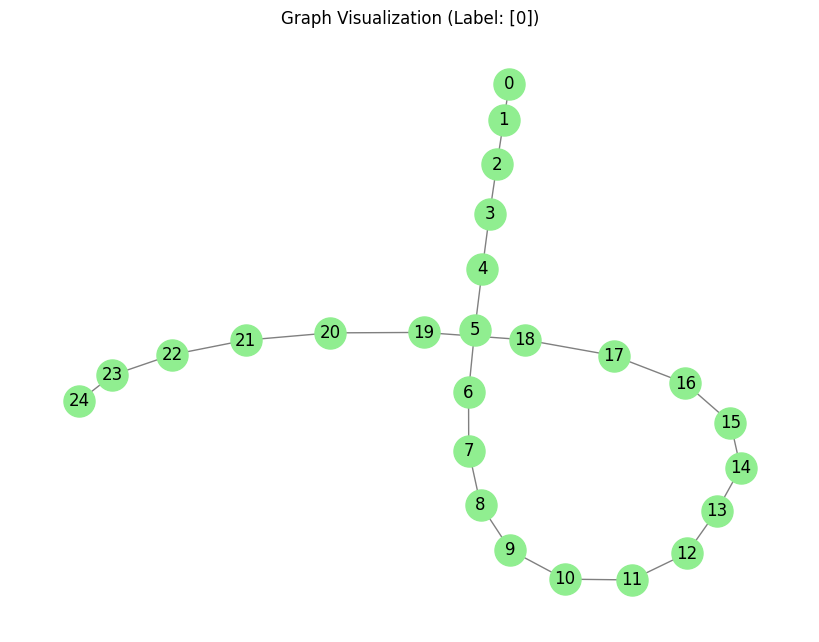

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Full path to the graph file
graph_path = r'C:\Users\admin\Desktop\pro\graph_data\graph_0.npz'  # You can change the index to visualize other graphs

# Load the .npz graph file
graph_data = np.load(graph_path, allow_pickle=True)

x = graph_data['x']        # Node features
edge_index = graph_data['edge_index']
y = graph_data['y']        # Class label

# Create a NetworkX graph from edge_index
G = nx.Graph()
edges = list(zip(edge_index[0], edge_index[1]))
G.add_edges_from(edges)

# Draw the graph
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)  # layout for consistent positioning
nx.draw(G, pos, with_labels=True, node_color='lightgreen', edge_color='gray', node_size=500)
plt.title(f'Graph Visualization (Label: {y})')
plt.show()


In [25]:
import numpy as np
import os

folder = import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.loader import DataLoader
from torch_geometric.data import Data
from sklearn.model_selection import train_test_split

# 🧠 Define the GCN model
class GCN(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

# 📦 Load your graph data
graph_list = torch.load("processed_graphs.pt")

# ✅ Extract dimensions
input_dim = graph_list[0].x.shape[1]
output_dim = torch.max(torch.stack([g.y for g in graph_list])).item() + 1

# 🪓 Split the data
train_graphs, test_graphs = train_test_split(graph_list, test_size=0.2, random_state=42)

train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=32)

# 🚀 Training setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GCN(input_dim, 64, output_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = torch.nn.NLLLoss()

# 🔁 Train the model
def train():
    model.train()
    total_loss = 0
    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data)
        loss = criterion(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)

# 🎯 Evaluate
def test(loader):
    model.eval()
    correct = 0
    total = 0
    for data in loader:
        data = data.to(device)
        out = model(data)
        pred = out.argmax(dim=1)
        correct += (pred == data.y).sum().item()
        total += data.num_nodes
    return correct / total

# 🧪 Run training
for epoch in range(1, 51):
    loss = train()
    acc = test(test_loader)
    print(f"Epoch {epoch:03d}, Loss: {loss:.4f}, Test Acc: {acc:.4f}")
'
file_list = [f for f in os.listdir(folder) if f.endswith('.npz')]

graphs = []
for file in file_list:
    data = np.load(os.path.join(folder, file), allow_pickle=True)
    graphs.append({
        'x': data['x'],
        'edge_index': data['edge_index'],
        'y': data['y']
    })


In [26]:
from torch_geometric.data import Data

torch_graphs = []
for g in graphs:
    data = Data(
        x=torch.tensor(g['x'], dtype=torch.float),
        edge_index=torch.tensor(g['edge_index'], dtype=torch.long),
        y=torch.tensor(g['y'], dtype=torch.long)
    )
    torch_graphs.append(data)


In [27]:
torch.save(torch_graphs, 'graph_dataset.pt')


Found 1211 graph files.


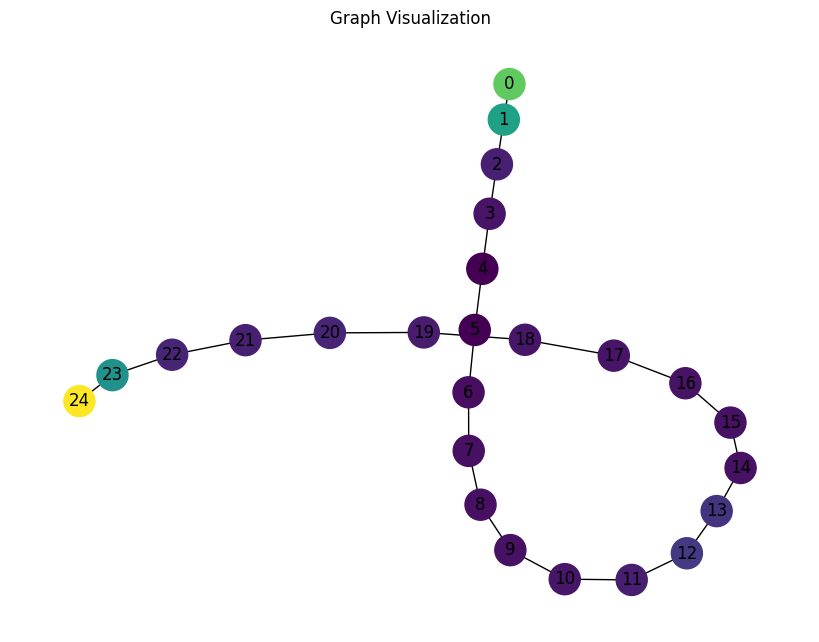

In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Set correct relative or absolute path
folder = 'graph_data'  # Since you're in /Desktop/pro/

# List .npz files
file_list = [f for f in os.listdir(folder) if f.endswith('.npz')]
print(f"Found {len(file_list)} graph files.")

# Load the first graph
graph_path = os.path.join(folder, file_list[0])
graph_data = np.load(graph_path, allow_pickle=True)

# Extract features
x = graph_data['x']  # Node features
edge_index = graph_data['edge_index']  # [2, num_edges]

# Build the graph using networkx
G = nx.Graph()
for i in range(x.shape[0]):
    G.add_node(i)

for src, dst in edge_index.T:
    G.add_edge(int(src), int(dst))

# Visualize
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)
node_colors = x[:, 0] if x.ndim > 1 else x  # Use first feature or scalar

nx.draw(
    G, pos,
    with_labels=True,
    node_color=node_colors,
    cmap='viridis',
    node_size=500
)
plt.title("Graph Visualization")
plt.show()


In [30]:
import torch
from torch_geometric.data import Data
from torch.serialization import add_safe_globals

# Allow PyG Data object to be deserialized (trust the source)
add_safe_globals([Data])

# Now load the full graph dataset
dataset = torch.load("graph_dataset.pt", weights_only=False)


In [32]:
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split

# Assuming dataset is a list of torch_geometric.data.Data objects
train_data, test_data = train_test_split(dataset, test_size=0.2, random_state=42)
train_data, val_data = train_test_split(train_data, test_size=0.1, random_state=42)

# Create loaders
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)


In [45]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.loader import DataLoader
from torch_geometric.data import Data
from sklearn.model_selection import train_test_split

# 🧠 Define the GCN model
class GCN(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, output_dim)

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        return F.log_softmax(global_mean_pool(x, batch), dim=1)


# 📦 Load the processed graph dataset
graph_list = torch.load('C:\\Users\\admin\\Desktop\\pro\\graph_dataset.pt', weights_only=False)

# ✅ Extract feature and output dimensions
input_dim = graph_list[0].x.shape[1]
output_dim = torch.max(torch.stack([g.y for g in graph_list])).item() + 1

# 🪓 Split the dataset into train and test sets
train_graphs, test_graphs = train_test_split(graph_list, test_size=0.2, random_state=42)

# 📥 Create DataLoaders
train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=32)

# 🚀 Initialize the model and optimizer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GCN(input_dim=input_dim, hidden_dim=64, output_dim=output_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = torch.nn.NLLLoss()

# 🔁 Training function
def train():
    model.train()
    total_loss = 0
    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)


# 🎯 Testing function
def test(loader):
    model.eval()
    correct = 0
    total = 0
    for data in loader:
        data = data.to(device)
        out = model(data.x, data.edge_index, data.batch)
        pred = out.argmax(dim=1)
        correct += int((pred == data.y).sum())
        total += data.y.size(0)
    return correct / total


# 🧪 Run training loop
for epoch in range(1, 51):
    loss = train()
    acc = test(test_loader)
    print(f"Epoch {epoch:03d}, Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")


Epoch 001, Loss: 20.2128, Test Accuracy: 0.4115
Epoch 002, Loss: 3.5455, Test Accuracy: 0.5473
Epoch 003, Loss: 2.9226, Test Accuracy: 0.6008
Epoch 004, Loss: 2.3014, Test Accuracy: 0.7202
Epoch 005, Loss: 2.1759, Test Accuracy: 0.4774
Epoch 006, Loss: 3.5573, Test Accuracy: 0.6337
Epoch 007, Loss: 1.6787, Test Accuracy: 0.6749
Epoch 008, Loss: 1.1014, Test Accuracy: 0.5720
Epoch 009, Loss: 1.3638, Test Accuracy: 0.7202
Epoch 010, Loss: 1.0084, Test Accuracy: 0.7572
Epoch 011, Loss: 1.4857, Test Accuracy: 0.6543
Epoch 012, Loss: 1.2565, Test Accuracy: 0.7695
Epoch 013, Loss: 1.0763, Test Accuracy: 0.6790
Epoch 014, Loss: 0.9880, Test Accuracy: 0.7037
Epoch 015, Loss: 1.1034, Test Accuracy: 0.7737
Epoch 016, Loss: 0.9484, Test Accuracy: 0.7078
Epoch 017, Loss: 1.0999, Test Accuracy: 0.6790
Epoch 018, Loss: 1.3194, Test Accuracy: 0.7407
Epoch 019, Loss: 0.8952, Test Accuracy: 0.7531
Epoch 020, Loss: 1.0201, Test Accuracy: 0.6008
Epoch 021, Loss: 1.5836, Test Accuracy: 0.6461
Epoch 022, L

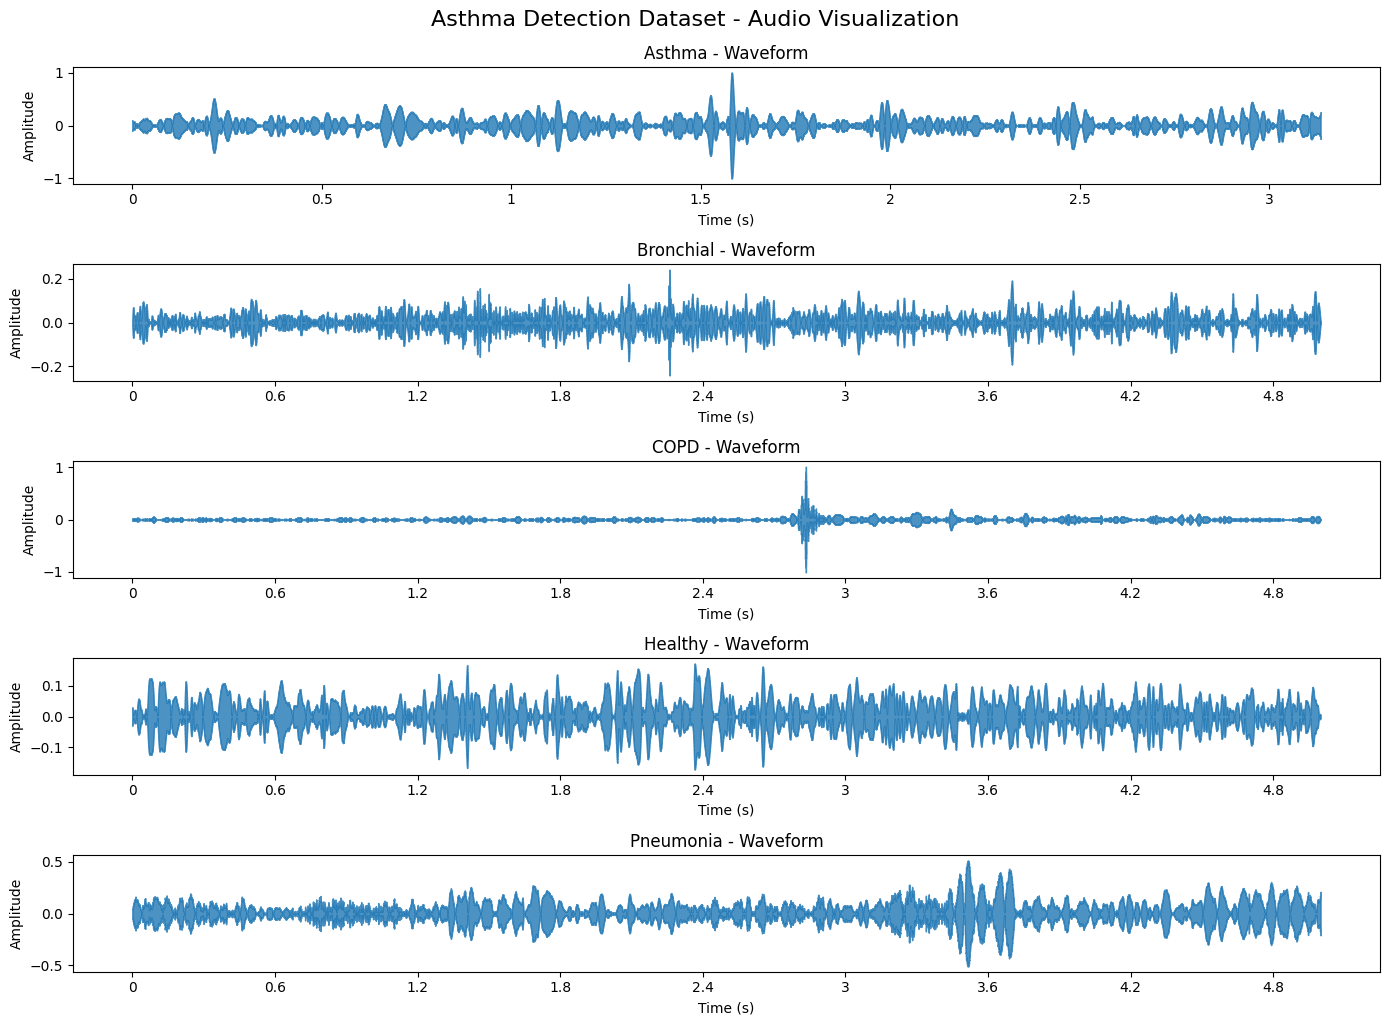

✅ Visualization saved as 'asthma_dataset_visualization.png'


In [7]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Define dataset path (update this to your dataset folder)
base_path = "Asthma Detection Dataset Version 2"

# Define classes
classes = ["Asthma", "Bronchial", "COPD", "Healthy", "Pneumonia"]

# Parameters
sample_rate = 22050  # resample to a common rate
duration = 5         # seconds (if you want fixed length)
n_fft = 2048
hop_length = 512

plt.figure(figsize=(14, 10))

for i, cls in enumerate(classes, 1):
    # Get one sample file from each class
    class_path = os.path.join(base_path, cls)
    file_name = os.listdir(class_path)[0]  # take first .wav
    file_path = os.path.join(class_path, file_name)

    # Load and resample
    y, sr = librosa.load(file_path, sr=sample_rate, duration=duration)

    # Compute frequency spectrum
    fft = np.fft.fft(y)
    magnitude = np.abs(fft)
    freq = np.linspace(0, sr, len(magnitude))

    # Use only first half of spectrum (real frequencies)
    half = len(freq)//2
    freq = freq[:half]
    magnitude = magnitude[:half]

    # Plot waveform
    plt.subplot(5, 1, i)
    librosa.display.waveshow(y, sr=sr, alpha=0.8)
    plt.title(f"{cls} - Waveform")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.suptitle("Asthma Detection Dataset - Audio Visualization", fontsize=16, y=1.02)

# ✅ Save the figure as a high-quality PNG image
plt.savefig("Wave_data_visual.png", dpi=300, bbox_inches='tight')

plt.show()

print("✅ Visualization saved as 'asthma_dataset_visualization.png'")
